# **Hashing**

## **Chaining** 

Chaining helps to keep the searching O(1) but at some extend and then it starts behaving like O(n), to avoid this we have two options 
1. tree
2. rehashing

### **Rehasing** based on load factor , it depends on size and capacity

$\textrm{load factor}=\frac{Size}{Capacity}$

In below diagram capacity is 4 and size is 6, 4/6= 1.5<-  load factor

load_factor should be below threshold and when this condition is false, then i resize the current array to 2*size or increase with some constant value.

when i am keep adding nodes and total count of nodes is showing size and capacity is showing array size.

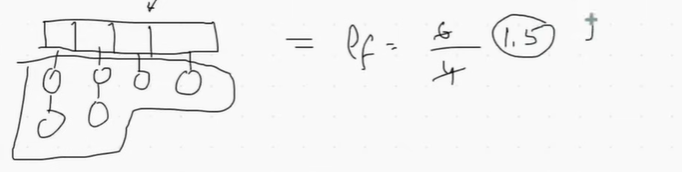

After creating new array , for each node i will calculate the hash again and will insert the node to new array based on the index position.

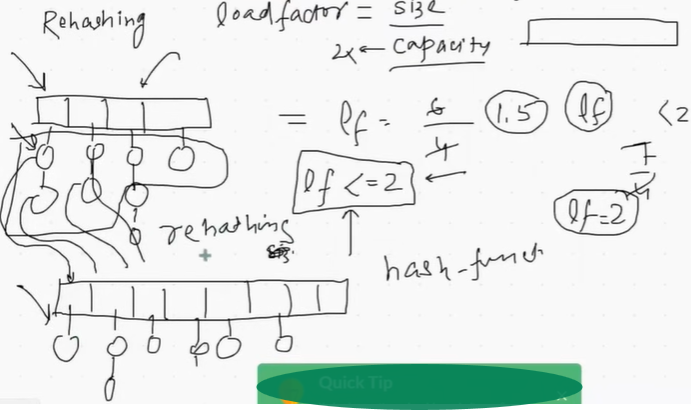



In [216]:
class Node:
    def __init__(self, key, value):
        self.key = key
        self.data = value
        self.next = None

In [217]:
class LinkedList:
    def __init__(self):

        # create a empty linkedlist (there are 0 nodes)
        # how to find if linkedlist is empty -> using head means it is going to be none.

        self.head = None

    def add(self, key, value):

        new_node = Node(key, value)

        if self.head == None:
            self.head = new_node
            print("ll.add(): ",self.head.key, self.head.data)
        else:
            temp = self.head

            while temp.next != None:
                temp = temp.next

            temp.next = new_node

    # delete head node
    def delete_head(self):
        # empty list
        if self.head == None:
            return "Empty LinkedList."

        self.head = self.head.next
        self.n -= 1

    def remove(self, key):
        if self.head.key == key:
            self.delete_head()
            return
        else:
            temp = self.head
            while temp.next != None:
                if temp.next.key == key:
                    break
                temp = temp.next

            if temp.next == None:
                return "Not Found"
            else:
                temp.next = temp.next.next

    def traverse(self):
        temp = self.head
        
        while temp != None:
            print(temp.key, "-->", temp.data, " ", end=" ")
            temp = temp.next
            
    def size(self):
        temp = self.head
        
        counter = 0
        
        while temp != None:
            counter += 1
            temp = temp.next
            
        return counter

    def search(self, key):
        temp = self.head

        pos = 0

        while temp != None:
            if temp.key == key:
                return pos
            temp = temp.next
            pos += 1
        return -1

    def get_node_at_index(self, index):
        temp = self.head
        counter = 0
        while temp != None:
            if counter == index:
                return temp
            temp = temp.next
            counter += 1

In [218]:
class Dictionary:
    def __init__(self, capacity):

        self.capacity = capacity
        self.size = 0
        # create array of LL
        self.buckets = self.make_array(
            self.capacity
        )  # every linkedlist is considered as bucket

    def make_array(self, capacity):
        L = []  # created an empty list

        # why not to use L = [LL()] *3 , this will point to one common object means it will point to common address , changing one value will change all 3 fields in array
        for i in range(capacity):
            L.append(LinkedList())

        return L

    def __setitem__(self, key, value):
        self.put(key, value)

    def __getitem__(self, key):
        return self.get(key)

    def __delitem__(self, key):
        bucket_index = self.hash_function(key)
        self.buckets[bucket_index].remove(key)
        
    def __str__(self):
        for i in self.buckets: # i is linkedlist
            i.traverse()
            
        return ""
        
    def get(self, key):
        """
        when i have array of linkedlist and i want to find a specific key then what do we need to do.


        """
        bucket_index = self.hash_function(key)

        res = self.buckets[bucket_index].search(key)

        if res == -1:
            return "Not Found"
        else:
            node = self.buckets[bucket_index].get_node_at_index(res)

            return node.data

    def put(self, key, value):

        # calculate hash value
        bucket_index = self.hash_function(
            key
        )  # this will give me position value in array and this is a bucket index
        # two possibilities 1. nothing is there in bucket position ,2. there are set of nodes already available.
        # when there are set of nodes at bucket position 1 (it can be anything but always below capacity), i will search for key , if found then update its value with new value , else add a new node at the tail.

        node_index = self.get_node_index(bucket_index, key)

        # if not found
        if node_index == -1:
            # insert
            print(key, value)
            self.buckets[bucket_index].add(key, value)
            self.size += 1

            load_factor = self.size / self.capacity
            print("load_factor :", load_factor)
            if self.size / self.capacity >= 2:  # 2 is load factor here
                # call rehash
                self.rehash()
        else:
            # key found then update
            node = self.buckets[bucket_index].get_node_at_index(node_index)
            node.data = value
            print(node, node.key, node.data)

    def rehash(self):
        # double the capacity
        self.capacity = self.capacity * 2

        # save buckets to new array
        old_buckets = self.buckets

        self.size = 0

        self.buckets = self.make_array(self.capacity)

        for i in old_buckets:
            """
            i is going to be one linked list
            so, i will traverse to all nodes and then for each node i will simply call put()
            """
            for j in range(i.size()):
                node = i.get_node_at_index(j)
                key_item = node.key
                value_item = node.data
                self.put(key_item, value_item)

    def get_node_index(self, bucket_index, key):
        curr_array_pos = self.buckets[
            bucket_index
        ]  # where self.buckets is an array and bucket_index is the position in that array and this complete variable is linked list where i can apply all linkedlist methods.

        # so i can call search method and find the position value
        node_index = curr_array_pos.search(key)

        return node_index

    def hash_function(self, key):
        return abs(hash(key)) % self.capacity

get item
traverse
delete

In [219]:
D1 = Dictionary(4)

In [230]:
D1.put("ruby", 20000)
D1.put("R", 50000)
D1.put("Java", 100000)
D1.put("matlab", 100000)
D1.put("python", 100000)

<__main__.Node object at 0x0000023E23443620> ruby 20000
<__main__.Node object at 0x0000023E236B4410> R 50000
Java 100000
ll.add():  Java 100000
load_factor : 1.0
matlab 100000
load_factor : 1.25
python 100000
ll.add():  python 100000
load_factor : 1.5


In [226]:
D1["c"]=45

<__main__.Node object at 0x0000023E236B42D0> c 45


In [228]:
D1["python1"]

'Not Found'

In [223]:
D1["Matlab"]

'Not Found'

In [233]:
print(D1)

ruby --> 20000   c --> 45   R --> 50000   Java --> 100000   python --> 100000   


In [232]:
del D1["matlab"]

In [198]:
D1.buckets

In [109]:
D1.buckets[2].traverse()

In [118]:
D1.buckets[0].traverse()

c --> 1000   ruby --> 20000   

In [119]:
D1.buckets[1].traverse()

c++ --> 5000   

In [120]:
D1.buckets[2].traverse()

Java --> 6   php --> 10000   

In [121]:
D1.buckets[3].traverse()

Python --> 100   

In [111]:
D1.put("Java", 56)

Java 56
ll.add():  Java 56


In [112]:
D1.put("Java", 6)

<__main__.Node object at 0x0000023E22CD8690> Java 6


In [113]:
D1.put("Python", 100)

<__main__.Node object at 0x0000023E22B6D940> Python 100


In [114]:
D1.put("c", 1000)

c 1000
ll.add():  c 1000


In [115]:
D1.put("c++", 5000)

c++ 5000
ll.add():  c++ 5000


In [116]:
D1.put("php", 10000)

php 10000


In [117]:
D1.put("ruby", 20000)

ruby 20000
